# Step 1: The decomposition

Is the decline in message volume (about two thirds from 2022 to 2025) driven by people leaving,
or by the same people posting less?

The group is a closed one of about 50 people, with two confirmed departures and two confirmed
arrivals over six years. "Active members" (at least 12 messages in a year) is therefore mostly a
measure of behaviour: falling below the bar usually means going quiet, not leaving. The
membership section at the end separates the two.

The headline comparison is 2022 → 2025, both full calendar years. 2026 is plotted but never used
as an endpoint (see the robustness section).

The queries come from `sql/01_decomposition.sql`. Their results are written to
`outputs/tables/`, and everything after that reads only from those CSVs.

In [1]:
import re
import os
import warnings
import psycopg2
import pandas as pd

warnings.filterwarnings("ignore", message=".*only supports SQLAlchemy.*")

REPO_ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
SQL_PATH = os.path.join(REPO_ROOT, "sql", "01_decomposition.sql")
TABLES_DIR = os.path.join(REPO_ROOT, "outputs", "tables")
os.makedirs(TABLES_DIR, exist_ok=True)

def load_labeled_queries(path):
    with open(path, encoding="utf-8") as f:
        sql = f.read()
    parts = re.split(r"--\s*QUERY:\s*(\w+)", sql)
    queries = {}
    for name, body in zip(parts[1::2], parts[2::2]):
        queries[name] = body.strip().rstrip(";")
    return queries

queries = load_labeled_queries(SQL_PATH)
print(f"Loaded {len(queries)} labeled queries: {list(queries.keys())}")

Loaded 12 labeled queries: ['yearly_totals', 'active_members_per_year', 'decomposition', 'member_lifecycle', 'window_check', 'cohort_decomposition', 'membership_events', 'member_year_text', 'yearly_text', 'turns_year', 'length_bands_year', 'media_year']


In [2]:
try:
    conn = psycopg2.connect(host="localhost", port=5432, dbname="postgres", user="postgres",
                            options="-c timezone=Europe/Bucharest")
except psycopg2.OperationalError:
    conn = None
    print("No database connection: using the saved tables in outputs/tables/.")
if conn is not None:
    for name, sql in queries.items():
        df = pd.read_sql(sql, conn)
        df.to_csv(os.path.join(TABLES_DIR, f"{name}.csv"), index=False)
        print(f"{name}: {len(df)} rows -> outputs/tables/{name}.csv")
    conn.close()

yearly_totals: 7 rows -> outputs/tables/yearly_totals.csv


active_members_per_year: 7 rows -> outputs/tables/active_members_per_year.csv


decomposition: 7 rows -> outputs/tables/decomposition.csv


member_lifecycle: 46 rows -> outputs/tables/member_lifecycle.csv


window_check: 7 rows -> outputs/tables/window_check.csv


...

member_year_text: 202 rows -> outputs/tables/member_year_text.csv


yearly_text: 7 rows -> outputs/tables/yearly_text.csv


turns_year: 21 rows -> outputs/tables/turns_year.csv


length_bands_year: 49 rows -> outputs/tables/length_bands_year.csv


media_year: 7 rows -> outputs/tables/media_year.csv


## Load from CSV only

From here on, everything reads from `outputs/tables/`.

In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid")
CHARTS_DIR = os.path.join(REPO_ROOT, "outputs", "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

yearly_totals            = pd.read_csv(os.path.join(TABLES_DIR, "yearly_totals.csv"))
active_members_per_year  = pd.read_csv(os.path.join(TABLES_DIR, "active_members_per_year.csv"))
decomposition            = pd.read_csv(os.path.join(TABLES_DIR, "decomposition.csv"))
member_lifecycle         = pd.read_csv(os.path.join(TABLES_DIR, "member_lifecycle.csv"))
window_check             = pd.read_csv(os.path.join(TABLES_DIR, "window_check.csv"))
cohort_decomposition     = pd.read_csv(os.path.join(TABLES_DIR, "cohort_decomposition.csv"))
membership_events        = pd.read_csv(os.path.join(TABLES_DIR, "membership_events.csv"))

PARTIAL_YEAR  = 2026
PRE_COMMUNITY = 2020
BASE_YEAR     = 2022
END_YEAR      = 2025

PARTIAL_NOTE = "2026 partial (Jan 1 - Aug 9); 2020 pre-community"

decomposition.round(1)

,year,total_messages,days_observed,messages_per_day,active_members,messages_per_active_member,messages_per_active_member_per_day
0,2020,1884,157,12.0,12,157.0,1.0
1,2021,325237,337,965.1,28,11615.6,34.5
2,2022,518795,365,1421.4,33,15721.1,43.1
3,2023,274665,365,752.5,31,8860.2,24.3
4,2024,220216,366,601.7,27,8156.1,22.3
5,2025,163052,365,446.7,28,5823.3,16.0
6,2026,109694,221,496.4,23,4769.3,21.6


## Chart 1: Total volume by year

2020 is kept but marked: 1,884 messages over 157 days, then 61 days of silence
(2020-11-29 → 2021-01-29). The community only really starts in 2021.

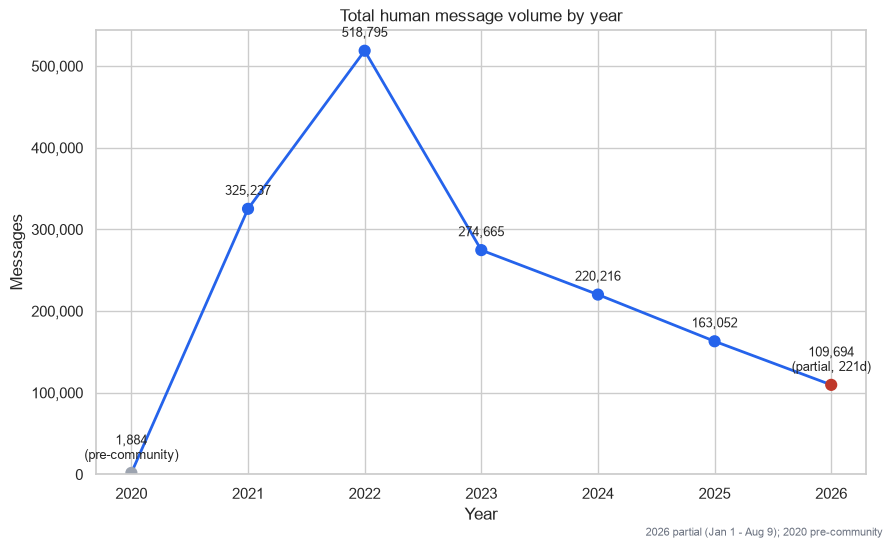

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))

def point_color(y):
    if y == PARTIAL_YEAR:
        return "#c0392b"
    if y == PRE_COMMUNITY:
        return "#9ca3af"
    return "#2563eb"

colors = [point_color(y) for y in yearly_totals["year"]]
ax.plot(yearly_totals["year"], yearly_totals["total_messages"], color="#2563eb", linewidth=2, zorder=1)
ax.scatter(yearly_totals["year"], yearly_totals["total_messages"], c=colors, s=60, zorder=2)
for _, row in yearly_totals.iterrows():
    label = f"{int(row.total_messages):,}"
    if row.year == PARTIAL_YEAR:
        label += f"\n(partial, {int(row.days_observed)}d)"
    if row.year == PRE_COMMUNITY:
        label += "\n(pre-community)"
    ax.annotate(label, (row.year, row.total_messages), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=9)
ax.set_title("Total human message volume by year")
ax.set_xlabel("Year")
ax.set_ylabel("Messages")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_xticks(yearly_totals["year"])
ax.set_ylim(bottom=0)
fig.text(0.99, 0.01, PARTIAL_NOTE, ha="right", fontsize=8, color="#6b7280")
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "01_total_volume_by_year.png"), dpi=150)
plt.show()

## Chart 2: Active members by year, at three thresholds

All three thresholds move together, so the shape doesn't depend on the choice of 12 messages.

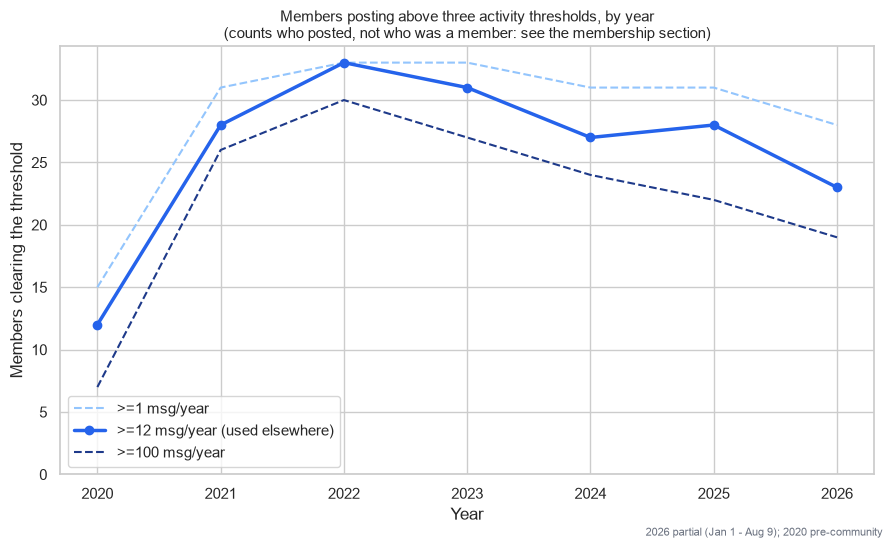

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(active_members_per_year["year"], active_members_per_year["active_ge1"],
        label=">=1 msg/year", linewidth=1.5, linestyle="--", color="#93c5fd")
ax.plot(active_members_per_year["year"], active_members_per_year["active_ge12"],
        label=">=12 msg/year (used elsewhere)", linewidth=2.5, color="#2563eb", marker="o")
ax.plot(active_members_per_year["year"], active_members_per_year["active_ge100"],
        label=">=100 msg/year", linewidth=1.5, linestyle="--", color="#1e3a8a")
ax.set_title("Members posting above three activity thresholds, by year\n"
             "(counts who posted, not who was a member: see the membership section)", fontsize=11)
ax.set_xlabel("Year")
ax.set_ylabel("Members clearing the threshold")
ax.set_xticks(active_members_per_year["year"])
ax.set_ylim(bottom=0)
ax.legend()
fig.text(0.99, 0.01, PARTIAL_NOTE, ha="right", fontsize=8, color="#6b7280")
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "02_active_members_by_year.png"), dpi=150)
plt.show()

## Chart 3: Messages per active member, per day

Per day rather than per year, so the partial 2026 isn't understated.

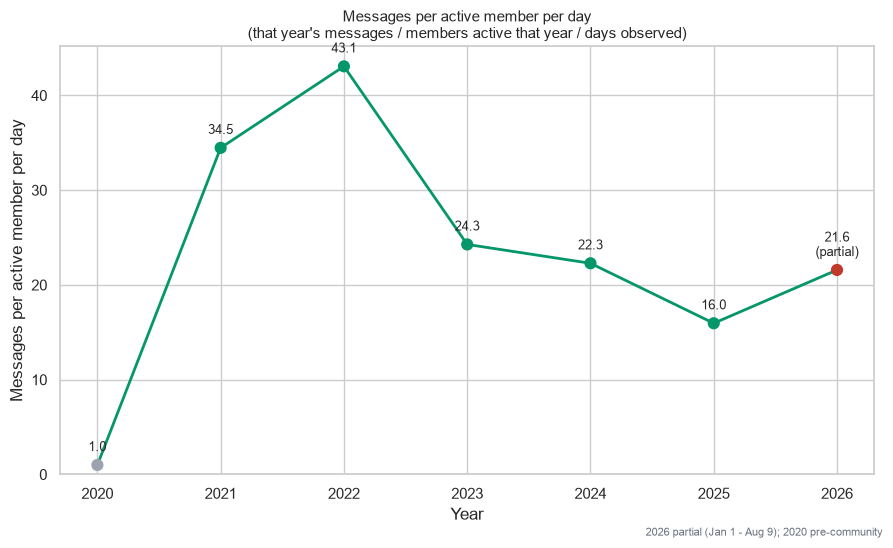

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(decomposition["year"], decomposition["messages_per_active_member_per_day"],
        color="#059669", linewidth=2, zorder=1)
ax.scatter(decomposition["year"], decomposition["messages_per_active_member_per_day"],
           c=["#c0392b" if y == PARTIAL_YEAR else ("#9ca3af" if y == PRE_COMMUNITY else "#059669")
              for y in decomposition["year"]], s=60, zorder=2)
for _, row in decomposition.iterrows():
    label = f"{row.messages_per_active_member_per_day:.1f}"
    if row.year == PARTIAL_YEAR:
        label += "\n(partial)"
    ax.annotate(label, (row.year, row.messages_per_active_member_per_day),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.set_title("Messages per active member per day\n"
             "(that year's messages / members active that year / days observed)", fontsize=11)
ax.set_xlabel("Year")
ax.set_ylabel("Messages per active member per day")
ax.set_xticks(decomposition["year"])
ax.set_ylim(bottom=0)
fig.text(0.99, 0.01, PARTIAL_NOTE, ha="right", fontsize=8, color="#6b7280")
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "03_messages_per_active_member.png"), dpi=150)
plt.show()

## Chart 4: The decomposition, indexed to 2022 = 100

Both series on one axis. "Indexed to 2022 = 100" means each line shows its value as a percentage
of its 2022 value, so two measures in different units can share one axis. The gap between the
lines shows how much more posting per member fell than the number of members.

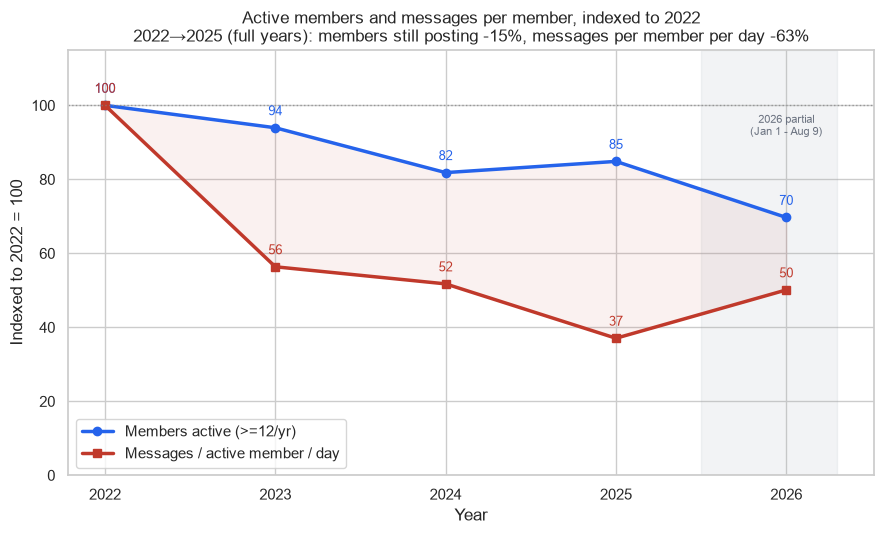

In [7]:
d = decomposition.set_index("year")
base = d.loc[BASE_YEAR]
idx = pd.DataFrame({
    "Members active (>=12/yr)":       100 * d["active_members"] / base["active_members"],
    "Messages / active member / day": 100 * d["messages_per_active_member_per_day"]
                                          / base["messages_per_active_member_per_day"],
}).loc[BASE_YEAR:]

fig, ax = plt.subplots(figsize=(9, 5.5))
styles = {"Members active (>=12/yr)": ("#2563eb", "o"),
          "Messages / active member / day": ("#c0392b", "s")}
for col, (color, marker) in styles.items():
    ax.plot(idx.index, idx[col], color=color, marker=marker, linewidth=2.5, label=col)
    for x, v in idx[col].items():
        ax.annotate(f"{v:.0f}", (x, v), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=9, color=color)

ax.axhline(100, color="grey", linestyle=":", linewidth=1, alpha=0.7)
ax.fill_between(idx.index, idx["Members active (>=12/yr)"],
                idx["Messages / active member / day"], color="#c0392b", alpha=0.07)
ax.axvspan(END_YEAR + 0.5, PARTIAL_YEAR + 0.3, color="#9ca3af", alpha=0.12)
ax.annotate("2026 partial\n(Jan 1 - Aug 9)", (PARTIAL_YEAR, 92), ha="center",
            fontsize=8, color="#6b7280")

pm = 100 * (d.loc[END_YEAR, "active_members"] / base["active_members"] - 1)
pi = 100 * (d.loc[END_YEAR, "messages_per_active_member_per_day"]
            / base["messages_per_active_member_per_day"] - 1)
ax.set_title(
    f"Active members and messages per member, indexed to {BASE_YEAR}\n"
    f"{BASE_YEAR}\u2192{END_YEAR} (full years): members still posting {pm:+.0f}%, "
    f"messages per member per day {pi:+.0f}%", fontsize=12)
ax.set_xlabel("Year")
ax.set_ylabel(f"Indexed to {BASE_YEAR} = 100")
ax.set_xticks(idx.index)
ax.set_ylim(0, 115)
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "04_decomposition_indexed.png"), dpi=150)
plt.show()

## Chart 5: Founding vs later posting cohorts

Two members above the inclusion floor first posted after the 2022 peak, both at high volume
(71,586 messages between them in 2024–2026). Splitting them out shows the trajectory of the
people who were there at the peak.

A cohort here is a group of members defined by when they first posted. For both later members,
the join event and the first post fall on the same day (2024-01-29 and 2024-01-30), so the first
post is a good stand-in for when they arrived. It isn't for founding members, several of whom
have more than one join event.

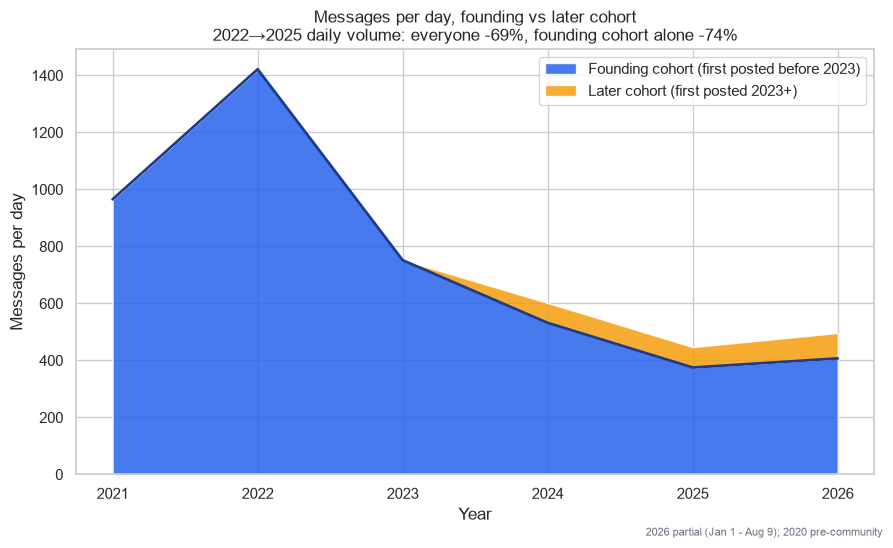

Later cohort contributed 71,586 messages across 2024-2026.


In [8]:
piv = cohort_decomposition.pivot(index="year", columns="cohort", values="messages_per_day").fillna(0)
piv = piv.loc[2021:]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.stackplot(piv.index, piv.get("founding", 0), piv.get("later", 0),
             labels=["Founding cohort (first posted before 2023)",
                     "Later cohort (first posted 2023+)"],
             colors=["#2563eb", "#f59e0b"], alpha=0.85)
ax.plot(piv.index, piv.get("founding", 0), color="#1e3a8a", linewidth=2)

f = cohort_decomposition[cohort_decomposition["cohort"] == "founding"].set_index("year")
dd = decomposition.set_index("year")
drop_all   = 100 * (dd.loc[END_YEAR, "messages_per_day"] / dd.loc[BASE_YEAR, "messages_per_day"] - 1)
drop_found = 100 * (f.loc[END_YEAR, "messages_per_day"] / f.loc[BASE_YEAR, "messages_per_day"] - 1)
later_total = int(cohort_decomposition[(cohort_decomposition["cohort"] == "later")
                                       & (cohort_decomposition["year"] >= 2024)]["total_messages"].sum())

ax.set_title(f"Messages per day, founding vs later cohort\n"
             f"{BASE_YEAR}\u2192{END_YEAR} daily volume: everyone {drop_all:+.0f}%, "
             f"founding cohort alone {drop_found:+.0f}%", fontsize=12)
ax.set_xlabel("Year")
ax.set_ylabel("Messages per day")
ax.set_xticks(piv.index)
ax.set_ylim(bottom=0)
ax.legend(loc="upper right")
fig.text(0.99, 0.01, PARTIAL_NOTE, ha="right", fontsize=8, color="#6b7280")
fig.tight_layout()
fig.savefig(os.path.join(CHARTS_DIR, "05_cohort_split.png"), dpi=150)
plt.show()

print(f"Later cohort contributed {later_total:,} messages across 2024-2026.")

## Robustness: why 2026 is never an endpoint

Every year recomputed on the same 1 January – 9 August window that 2026 covers.

1. On the same window, 2026 is still slightly above 2025. The rebound shrinks but doesn't
   disappear: the decline flattened after 2024.
2. The January–August window isn't neutral for a football server. It includes the summer
   tournaments of 2021, 2024 and 2026 but not the winter World Cup of 2022, so 2022 is the only
   year whose windowed rate is below its full-year rate.

Full calendar years avoid the partial-window problem but not the tournament cycle: 2021, 2022,
2024 and 2026 have a major tournament, 2023 and 2025 don't. June–July volume relative to the
year's monthly average is 1.85×, 1.43× and 1.35× in tournament years, against 0.97× and 1.05× in
2023 and 2025.

So the 2022 → 2025 comparison sets a tournament year against a year without one. Step 2
measures how much that matters.

The two years without a tournament (2023 → 2025) give −41% volume, −10% members and −34%
messages per member: smaller, but the same shape.

Read from 2022 onward; 2020 and 2021 cover the period before the community was established.

In [9]:
wc = window_check.set_index("year")
yt = yearly_totals.set_index("year")
cmp = pd.DataFrame({
    "window msgs/day":            wc["window_messages_per_day"],
    "full-year msgs/day":         yt["messages_per_day"],
    "active >=12 (window)":       wc["window_active_ge12"],
    "active >=7 (pro-rated bar)": wc["window_active_ge7"],
    "window msgs/active/day":     wc["window_msgs_per_active_member_per_day"],
})
cmp["window vs full-year"] = (cmp["window msgs/day"] / cmp["full-year msgs/day"] - 1).map(lambda v: f"{v:+.1%}")
cmp.round(1)

,window msgs/day,full-year msgs/day,active >=12 (window),active >=7 (pro-rated bar),window msgs/active/day,window vs full-year
year,,,,,,
2020,7.3,12.0,11,12,0.7,-39.0%
2021,648.7,965.1,22,22,29.5,-32.8%
2022,1345.9,1421.4,33,33,40.8,-5.3%
2023,806.0,752.5,31,31,26.0,+7.1%
2024,654.5,601.7,27,28,24.2,+8.8%
2025,482.2,446.7,25,26,19.3,+8.0%
2026,496.4,496.4,23,25,21.6,+0.0%


In [10]:
w25, w26 = wc.loc[2025], wc.loc[2026]
print("Like-for-like Jan 1 - Aug 9, 2025 vs 2026:")
print(f"  volume/day        {w25['window_messages_per_day']:.1f} -> {w26['window_messages_per_day']:.1f}"
      f"  ({w26['window_messages_per_day']/w25['window_messages_per_day']-1:+.1%})")
print(f"  msgs/active/day   {w25['window_msgs_per_active_member_per_day']:.1f} -> "
      f"{w26['window_msgs_per_active_member_per_day']:.1f}"
      f"  ({w26['window_msgs_per_active_member_per_day']/w25['window_msgs_per_active_member_per_day']-1:+.1%})")
print()
print("2022 is the only year where the window undershoots the full year")
print(f"  ({wc.loc[2022,'window_messages_per_day']:.1f} vs {yt.loc[2022,'messages_per_day']:.1f}/day)")
print("  because the Nov-Dec 2022 World Cup falls outside a Jan-Aug window.")

Like-for-like Jan 1 - Aug 9, 2025 vs 2026:
  volume/day        482.2 -> 496.4  (+2.9%)
  msgs/active/day   19.3 -> 21.6  (+11.9%)

2022 is the only year where the window undershoots the full year
  (1345.9 vs 1421.4/day)
  because the Nov-Dec 2022 World Cup falls outside a Jan-Aug window.


## Message length: the decline in text, not messages

Everything above counts messages. If people send fewer but longer messages, a message count
overstates how much less was written. So the 2022 → 2025 comparison is repeated in characters,
in characters without links, and in words. The change in message length is then split in two:

- **within members:** the same people writing longer messages;
- **composition:** a shift in who posts how much, toward people who always wrote longer messages
  (members present in only one of the two years count here).

In [11]:
member_year_text = pd.read_csv(os.path.join(TABLES_DIR, "member_year_text.csv"))
yearly_text = pd.read_csv(os.path.join(TABLES_DIR, "yearly_text.csv")).set_index("year")

yt = member_year_text.groupby("year")[["messages", "chars", "chars_no_urls", "words"]].sum()
yt["mean_chars"] = yt["chars"] / yt["messages"]
yt["median_chars"] = yearly_text["median_chars"]
print(yt.round(1).to_string())
print()
for col, lbl in [("messages", "messages"), ("chars", "characters"),
                 ("chars_no_urls", "characters, links removed"), ("words", "words")]:
    print(f"{BASE_YEAR} -> {END_YEAR}  {lbl:<26} {yt.loc[END_YEAR, col] / yt.loc[BASE_YEAR, col] - 1:+.1%}")

def within_split(df, y0, y1, num):
    """Symmetric split of the change in num-per-message into within-member
    change (weighted by each member's average message share) and the rest."""
    a = df[df["year"] == y0].set_index("pseudonym")
    b = df[df["year"] == y1].set_index("pseudonym")
    both = a.index.intersection(b.index)
    s0, s1 = a["messages"] / a["messages"].sum(), b["messages"] / b["messages"].sum()
    r0, r1 = a[num] / a["messages"], b[num] / b["messages"]
    total = b[num].sum() / b["messages"].sum() - a[num].sum() / a["messages"].sum()
    within = ((s0[both] + s1[both]) / 2 * (r1[both] - r0[both])).sum()
    return total, within

total, within = within_split(member_year_text, BASE_YEAR, END_YEAR, "chars")
print()
print(f"mean characters per message, {BASE_YEAR} -> {END_YEAR}: {total:+.2f}")
print(f"  within members (same people writing longer)  {within:+.2f}  ({within / total:.0%})")
print(f"  composition (who posts how much)              {total - within:+.2f}  ({1 - within / total:.0%})")

a = member_year_text[member_year_text["year"] == BASE_YEAR].set_index("pseudonym")
b = member_year_text[member_year_text["year"] == END_YEAR].set_index("pseudonym")
steady = [p for p in a.index.intersection(b.index)
          if a.loc[p, "messages"] >= 500 and b.loc[p, "messages"] >= 500]
longer = sum(b.loc[p, "chars"] / b.loc[p, "messages"] > a.loc[p, "chars"] / a.loc[p, "messages"]
             for p in steady)
print(f"{longer} of {len(steady)} members with 500+ messages in both years wrote longer messages in {END_YEAR}.")

      messages     chars  chars_no_urls    words  mean_chars  median_chars
year                                                                      
2020      1884     41832          40867     8418        22.2          16.0
2021    325237   8847594        8374310  1654681        27.2          20.0
2022    518795  15554166       14593046  2851901        30.0          21.0
2023    274665   9668049        9245664  1775463        35.2          26.0
2024    220216   8365767        7934296  1511925        38.0          28.0
2025    163052   6932902        6538519  1241305        42.5          30.0
2026    109694   4785571        4401735   836883        43.6          32.0

2022 -> 2025  messages                   -68.6%
2022 -> 2025  characters                 -55.4%
2022 -> 2025  characters, links removed  -55.2%
2022 -> 2025  words                      -56.5%

mean characters per message, 2022 -> 2025: +12.54
  within members (same people writing longer)  +7.10  (57%)
  composition (who po

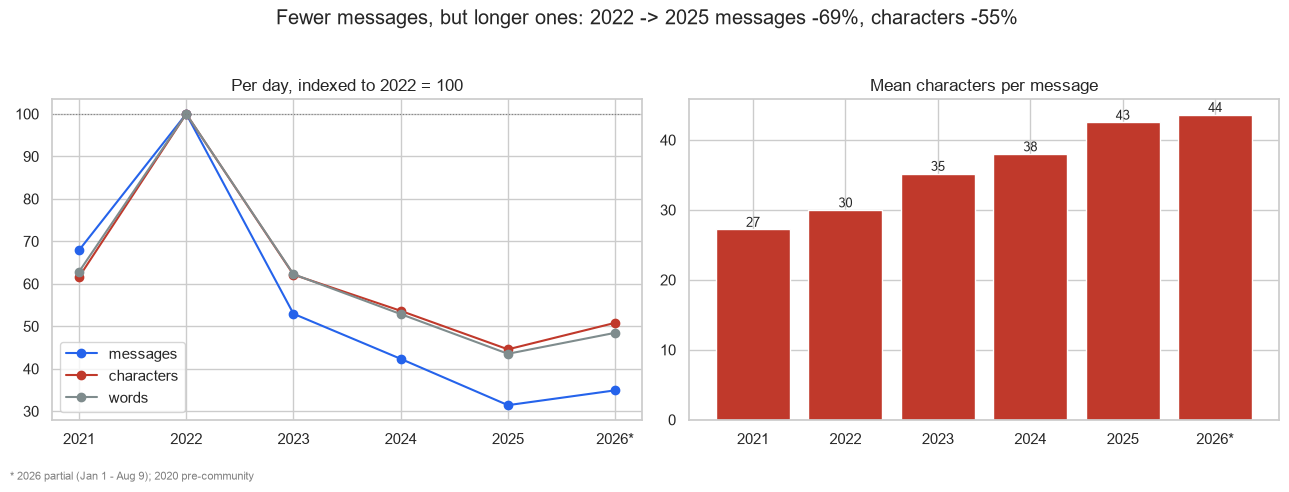

In [12]:
days = decomposition.set_index("year")["days_observed"]
yrs = [y for y in yt.index if y != PRE_COMMUNITY]
labels = [f"{y}*" if y == PARTIAL_YEAR else str(y) for y in yrs]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
for col, lbl, colour in [("messages", "messages", "#2563eb"), ("chars", "characters", "#c0392b"),
                         ("words", "words", "#7f8c8d")]:
    per_day = yt.loc[yrs, col] / days.loc[yrs]
    ax.plot(yrs, 100 * per_day / per_day.loc[BASE_YEAR], marker="o", label=lbl, color=colour)
ax.axhline(100, color="grey", lw=0.8, ls=":")
ax.set_title(f"Per day, indexed to {BASE_YEAR} = 100")
ax.legend()
ax = axes[1]
ax.bar(yrs, yt.loc[yrs, "mean_chars"], color="#c0392b")
for y in yrs:
    ax.annotate(f"{yt.loc[y, 'mean_chars']:.0f}", (y, yt.loc[y, "mean_chars"]),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Mean characters per message")
for x in axes:
    x.set_xticks(yrs)
    x.set_xticklabels(labels)
msg_chg = yt.loc[END_YEAR, "messages"] / yt.loc[BASE_YEAR, "messages"] - 1
chr_chg = yt.loc[END_YEAR, "chars"] / yt.loc[BASE_YEAR, "chars"] - 1
fig.suptitle(f"Fewer messages, but longer ones: {BASE_YEAR} -> {END_YEAR} messages {msg_chg:+.0%}, "
             f"characters {chr_chg:+.0%}")
fig.text(0.01, 0.0, "* " + PARTIAL_NOTE, fontsize=8, color="grey")
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(os.path.join(CHARTS_DIR, "22_message_length.png"), dpi=150)
plt.show()

In characters or words, the 2022 → 2025 decline is about **−55%**, not −69%:
messages got longer every year. Most of the lengthening is the same people writing longer
messages, and nearly every regular member did it. The decline is still large and still mostly
people posting less, but how people post changed too: fewer, longer messages. Characters are
only a rough stand-in for how much was said.

### Bursts, short messages, media

Three ways the decline could reflect how people post rather than how much:

- **bursts:** people used to split one thought over several quick messages and now send one.
  Each person's back-to-back messages are merged into one turn (another author's message ends
  it), at three gap lengths;
- **which messages went:** the drop by message length;
- **substitutes:** media, links and emoji reactions replacing text.

In [13]:
turns = pd.read_csv(os.path.join(TABLES_DIR, "turns_year.csv"))
bands = pd.read_csv(os.path.join(TABLES_DIR, "length_bands_year.csv"))
media = pd.read_csv(os.path.join(TABLES_DIR, "media_year.csv")).set_index("year")

print("Bursts: each person's back-to-back messages merged into one turn:")
for gap, g in turns.groupby("gap_seconds"):
    g = g.set_index("year")
    a, b = g.loc[BASE_YEAR], g.loc[END_YEAR]
    print(f"  within {gap:>3}s: turns {int(a['turns']):>9,} -> {int(b['turns']):>9,} "
          f"({b['turns'] / a['turns'] - 1:+.1%})   characters per turn "
          f"{a['chars'] / a['turns']:.1f} -> {b['chars'] / b['turns']:.1f}")
print(f"  messages, for comparison: {yt.loc[END_YEAR, 'messages'] / yt.loc[BASE_YEAR, 'messages'] - 1:+.1%}")
print()

bp = bands.pivot(index=["band_order", "band"], columns="year", values="messages").droplevel(0)
bp = bp.fillna(0).astype(int)
lost = bp[BASE_YEAR] - bp[END_YEAR]
print(f"Which messages disappeared, {BASE_YEAR} -> {END_YEAR}, by length in characters:")
for band, row in bp.iterrows():
    print(f"  {band:>8}  {row[BASE_YEAR]:>8,} -> {row[END_YEAR]:>7,}  "
          f"{row[END_YEAR] / row[BASE_YEAR] - 1:+5.0%}   {lost[band] / lost.sum():5.1%} of the missing messages")
print()

media["any_media_share"] = media["with_any_media"] / media["messages"]
media["reactions_per_100_msgs"] = 100 * media["reactions"] / media["messages"]
print("Media and reactions:")
print(media[["messages", "with_any_media", "any_media_share", "reactions",
             "reactions_per_100_msgs"]].round(3).to_string())
print(f"  Messages with an attachment, embed or link: "
      f"{media.loc[BASE_YEAR, 'any_media_share']:.1%} -> {media.loc[END_YEAR, 'any_media_share']:.1%} "
      f"of messages, but {media.loc[END_YEAR, 'with_any_media'] / media.loc[BASE_YEAR, 'with_any_media'] - 1:+.0%} "
      f"in number.")

Bursts: each person's back-to-back messages merged into one turn:
  within  30s: turns   380,759 ->   118,330 (-68.9%)   characters per turn 40.9 -> 58.6
  within  60s: turns   374,418 ->   112,933 (-69.8%)   characters per turn 41.5 -> 61.4
  within 120s: turns   371,760 ->   110,356 (-70.3%)   characters per turn 41.8 -> 62.8
  messages, for comparison: -68.6%

Which messages disappeared, 2022 -> 2025, by length in characters:
         0     9,710 ->   3,807   -61%    1.7% of the missing messages
       1-5    83,217 ->  14,785   -82%   19.2% of the missing messages
      6-20   157,092 ->  38,054   -76%   33.5% of the missing messages
     21-50   183,428 ->  61,375   -67%   34.3% of the missing messages
    51-100    71,328 ->  34,786   -51%   10.3% of the missing messages
   101-200    12,023 ->   8,459   -30%    1.0% of the missing messages
      201+     1,997 ->   1,786   -11%    0.1% of the missing messages

Media and reactions:
      messages  with_any_media  any_media_share 

## First and last message per member

This measures posting. Discord records when someone joins but not when they leave, so a long
silence at the end of a timeline could be dormancy or departure. The next cell uses the join
events to show what the data can establish.

In [14]:
included = member_lifecycle[member_lifecycle["is_included_member"]].copy()
included["last_message_date"] = pd.to_datetime(included["last_message_date"])
dataset_end = included["last_message_date"].max()
included["days_since_last_message"] = (dataset_end - included["last_message_date"]).dt.days
gone_quiet = included.sort_values("days_since_last_message", ascending=False).head(10)
gone_quiet[["pseudonym", "lifetime_message_count", "first_message_date",
            "last_message_date", "days_since_last_message", "distinct_years_with_activity"]]

,pseudonym,lifetime_message_count,first_message_date,last_message_date,days_since_last_message,distinct_years_with_activity
25,user_26,7063,2021-05-25,2022-05-11,1551,2
20,user_21,16978,2022-01-09,2023-04-02,1225,2
19,user_20,21714,2020-06-26,2023-05-05,1192,4
28,user_29,2190,2020-06-26,2026-03-22,140,7
24,user_25,9097,2021-11-02,2026-06-26,44,6
27,user_28,5452,2021-10-29,2026-07-12,28,6
8,user_09,62295,2021-05-09,2026-07-16,24,6
21,user_22,9868,2021-05-15,2026-07-20,20,6
7,user_08,66406,2021-05-08,2026-07-28,12,6
26,user_27,6013,2021-11-02,2026-07-29,11,6


In [15]:
n_included = len(included)
n_recent = (included["days_since_last_message"] <= 90).sum()
n_dormant = (included["days_since_last_message"] > 365).sum()
print(f"{n_included} members clear the 1,000-message inclusion floor.")
print(f"{n_recent} of them posted within the last 90 days of the dataset ({dataset_end.date()}).")
print(f"{n_included - n_recent} have been silent 90+ days; {n_dormant} for over a year.")
print()
print()
first_posted_late = included[pd.to_datetime(included["first_message_date"]) >= "2023-01-01"]
print(f"{len(first_posted_late)} included members first posted after the 2022 peak:")
print(first_posted_late[["pseudonym", "lifetime_message_count", "first_message_date"]].to_string(index=False))

29 members clear the 1,000-message inclusion floor.
25 of them posted within the last 90 days of the dataset (2026-08-09).
4 have been silent 90+ days; 3 for over a year.


2 included members first posted after the 2022 peak:
pseudonym  lifetime_message_count first_message_date
  user_13                   47646         2024-01-30
  user_19                   23772         2024-01-29


## Membership: what the join events can and can't show

The export has 153 human `GuildMemberJoin` rows ("Joined the server."), covering 49 of the 50
authors, so joins are observable. Leaves aren't:

- `join_count > 1` means at least `join_count - 1` departures happened, since a rejoin implies a
  leave. It's a minimum, not a count.
- A member who left for good looks the same as one who stopped posting.

That's why Step 5 asks when someone went quiet, never when they left. What's known about
specific members is kept in `mapping_private/membership_notes.md`, outside the repository.

In [16]:
me = membership_events[membership_events["is_included_member"]].copy()
churn = me[me["join_count"] > 1].sort_values("join_count", ascending=False)

print(f"{len(me)} members above the inclusion floor")
print(f"  {(me['join_count'] == 1).sum()} joined exactly once")
print(f"  {len(churn)} have multiple join events -> at least "
      f"{int(churn['min_departures_implied'].sum())} departures happened and were reversed")
print(f"  {int(me['min_departures_implied'].max())} = most rejoins by a single member "
      f"(half the total, from one person)")
print(f"  {(me['join_count'] == 0).sum()} has no join event at all, consistent with being the")
print("    account that created the server, which never generates a join message")
print()
exact = me[me["first_post_matches_join"] == True]
print(f"First post lands on the join date for {len(exact)} of {len(me)} members")
print("(for those, first-post is an exact proxy for arrival)")
print()
churn.head(8)[["pseudonym", "lifetime_message_count", "join_count",
               "min_departures_implied", "last_join_date", "last_post_date",
               "days_silent_at_export_end"]]

29 members above the inclusion floor
  15 joined exactly once
  13 have multiple join events -> at least 101 departures happened and were reversed
  51 = most rejoins by a single member (half the total, from one person)
  1 has no join event at all, consistent with being the
    account that created the server, which never generates a join message

First post lands on the join date for 27 of 29 members
(for those, first-post is an exact proxy for arrival)



,pseudonym,lifetime_message_count,join_count,min_departures_implied,last_join_date,last_post_date,days_silent_at_export_end
19,user_20,21714,52,51,2023-03-30,2023-05-05,1192
0,user_01,218769,15,14,2022-10-29,2026-08-09,0
5,user_06,103427,8,7,2022-10-29,2026-08-09,0
6,user_07,95584,8,7,2021-12-10,2026-08-09,0
16,user_17,27205,8,7,2022-01-04,2026-08-06,3
1,user_02,185596,4,3,2021-10-14,2026-08-09,0
3,user_04,127720,4,3,2022-01-13,2026-08-09,0
4,user_05,116909,3,2,2021-10-31,2026-08-09,0
